In [8]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

In [9]:
ds = xr.open_dataset("/scratch/imaging/connectome-variability/four-individual-subjects.nc")
ds

<xarray.Dataset> Size: 6GB
Dimensions:                  (cell: 79800, iteration: 100, pipeline: 25,
                              subject: 4)
Coordinates:
  * cell                     (cell) <U56 18MB 'LH_Vis_2, LH_Vis_1' ... 'RH_De...
  * iteration                (iteration) int64 800B 0 1 2 3 4 ... 95 96 97 98 99
  * pipeline                 (pipeline) <U28 3kB 'GSR' ... 'motionParametersS...
  * subject                  (subject) <U9 144B 'sub-01' 'sub-09' ... 'sub-9040'
Data variables:
    functional_connectivity  (cell, iteration, pipeline, subject) float64 6GB ...

In [10]:
ds.functional_connectivity.shape

(79800, 100, 25, 4)

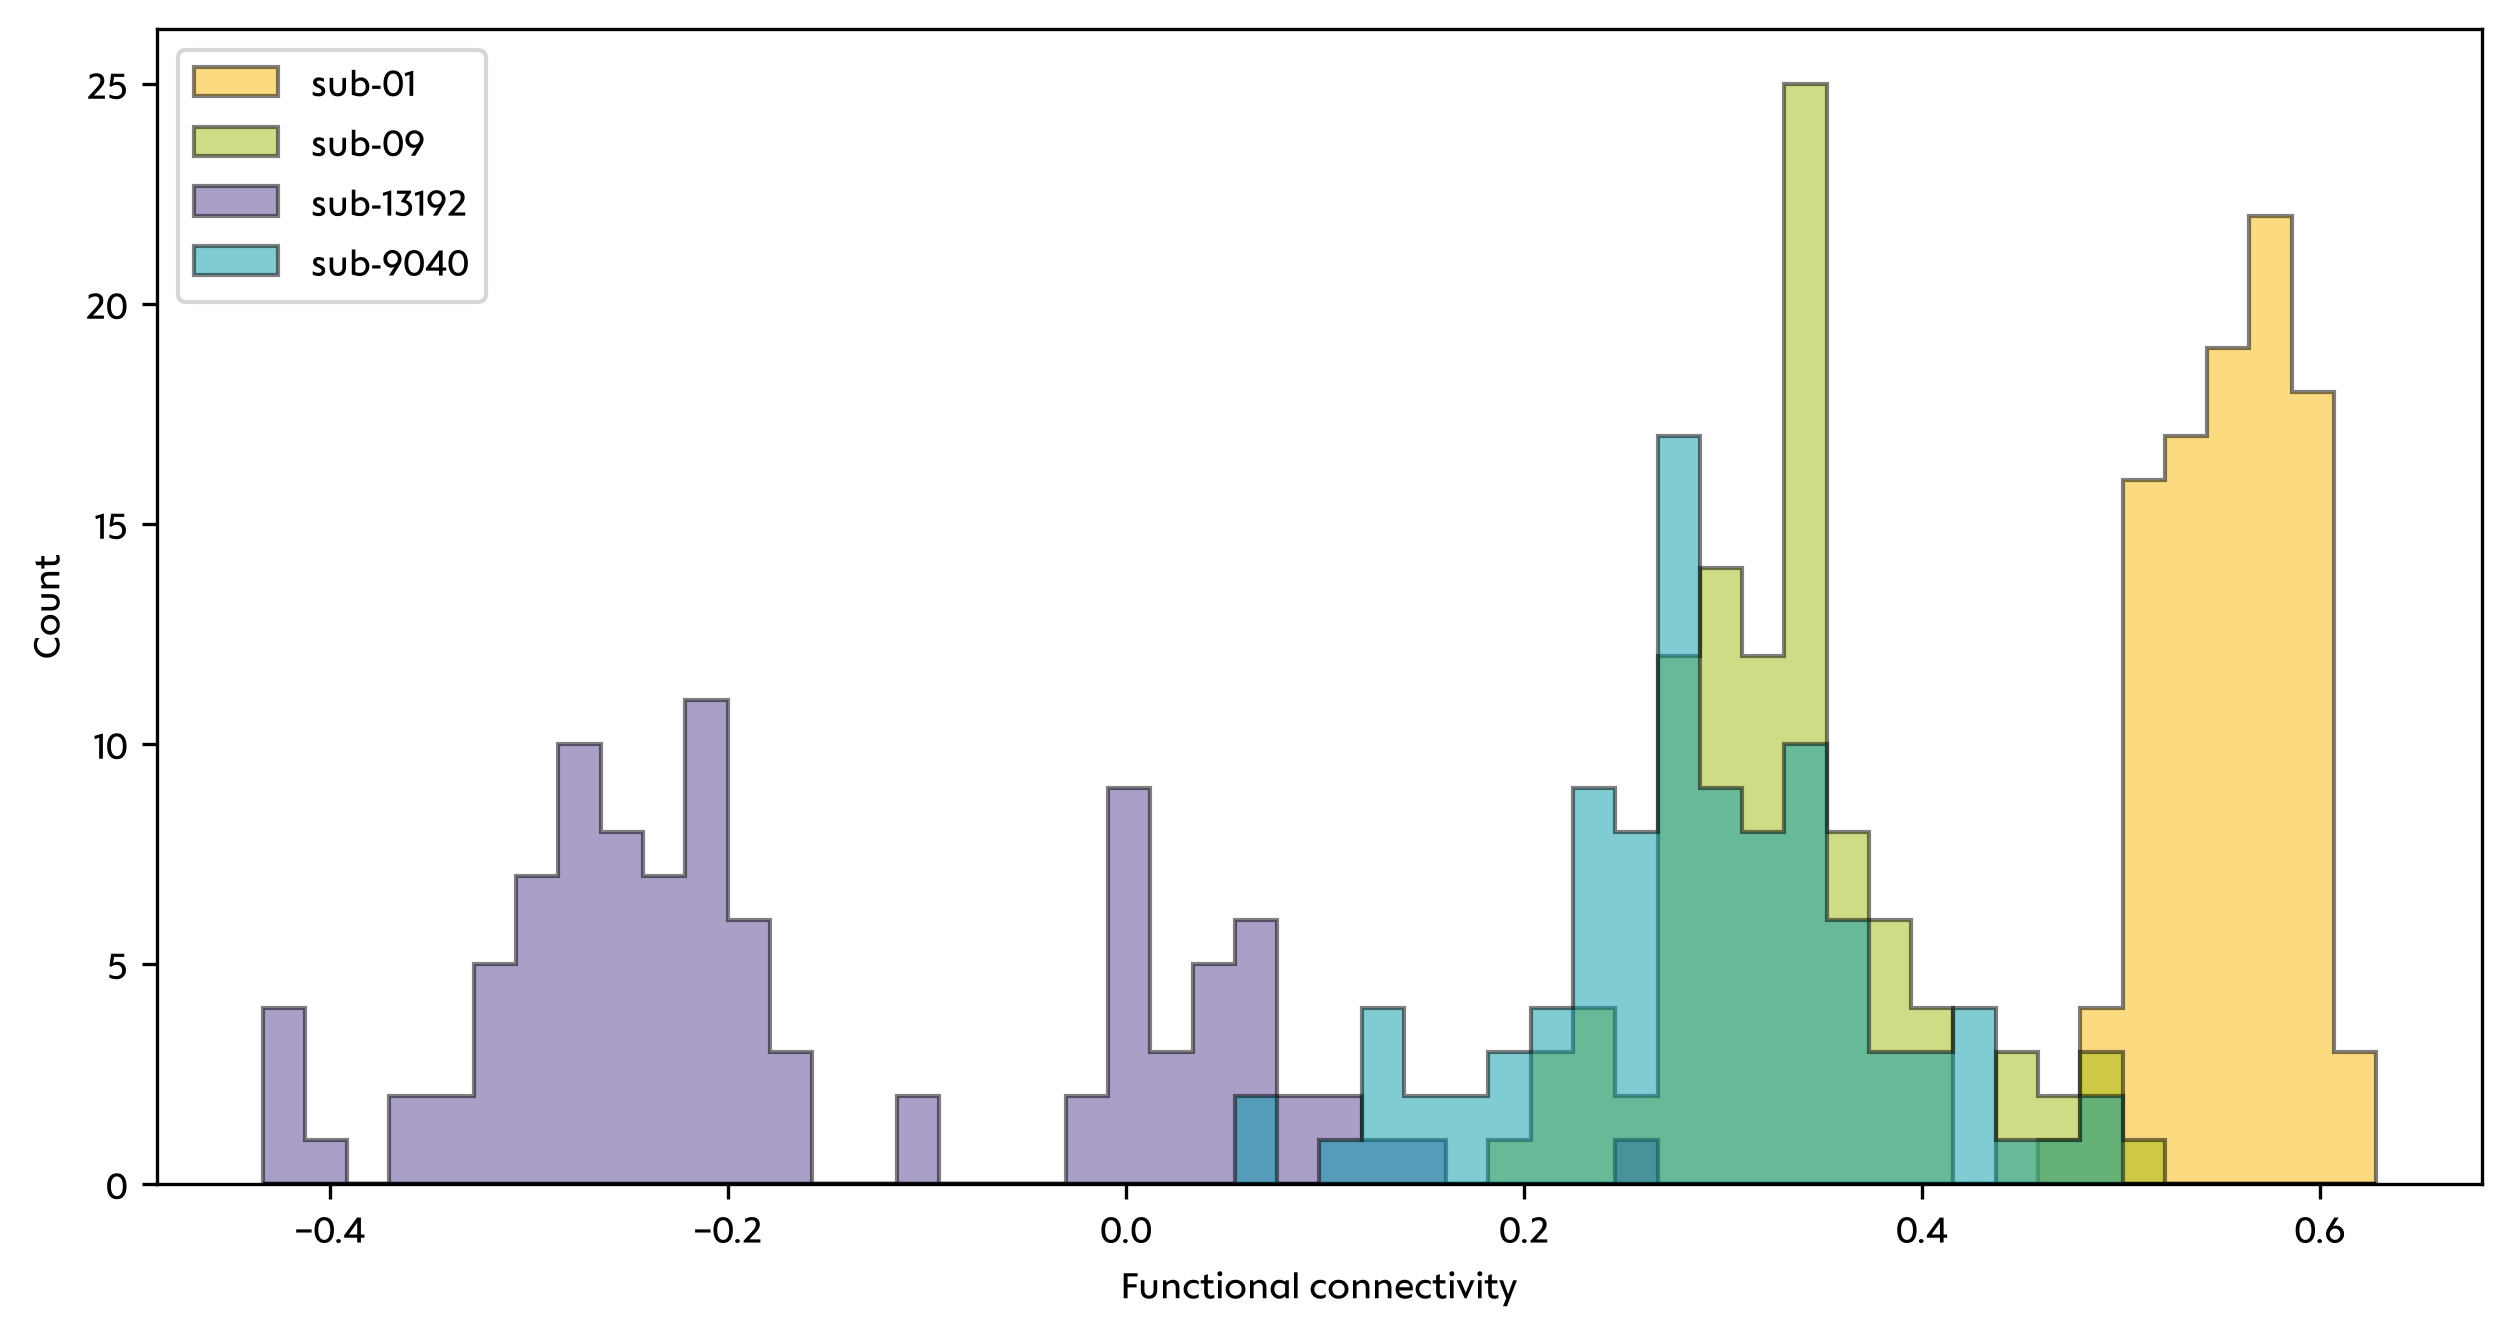

In [11]:
import numpy as np
from matplotlib import pyplot as plt

GRASGRUEN    = "#a1ba0c"
MINERAL      = "#009aa9"
LILA         = "#564091"
MANGO        = "#fab600"

font_family = "Charité Text Office"
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": [f"{font_family}"],
        "mathtext.fontset": "custom",
        "mathtext.rm": f"{font_family}",
        "mathtext.it": f"{font_family}:italic",
        "mathtext.bf": f"{font_family}:bold",
        "mathtext.bfit": f"{font_family}:bold:italic",
        "mathtext.sf": f"{font_family}",
    }
)

# PCC/mPFC functional connectivity (right hemisphere), overlaid across subjects
cell_index = 76626  # 76626
pipeline = "icaAromaMotionParameters"

colors = {"sub-01": MANGO, "sub-09": GRASGRUEN, "sub-9040": MINERAL, "sub-13192": LILA}

all_data = ds.functional_connectivity[cell_index].sel(pipeline=pipeline).values
bins = np.histogram_bin_edges(all_data[np.isfinite(all_data)], bins=50)

figure = plt.figure(figsize=(10, 5), dpi=300)
for subject in ds.subject.values:
    data = ds.functional_connectivity[cell_index].sel(
        pipeline=pipeline, subject=subject
    )
    plt.hist(
        data,
        bins=bins,
        alpha=0.5,
        histtype="stepfilled", 
        label=subject,
        color=colors.get(subject),
        edgecolor="black",
    )

# plt.title(f"PCC/mPFC functional connectivity (right hemisphere)\nPipeline {pipeline}")
plt.xlabel("Functional connectivity")
plt.ylabel("Count")
plt.legend()

figure.savefig("histogram.svg", bbox_inches="tight", pad_inches=0, transparent=True)

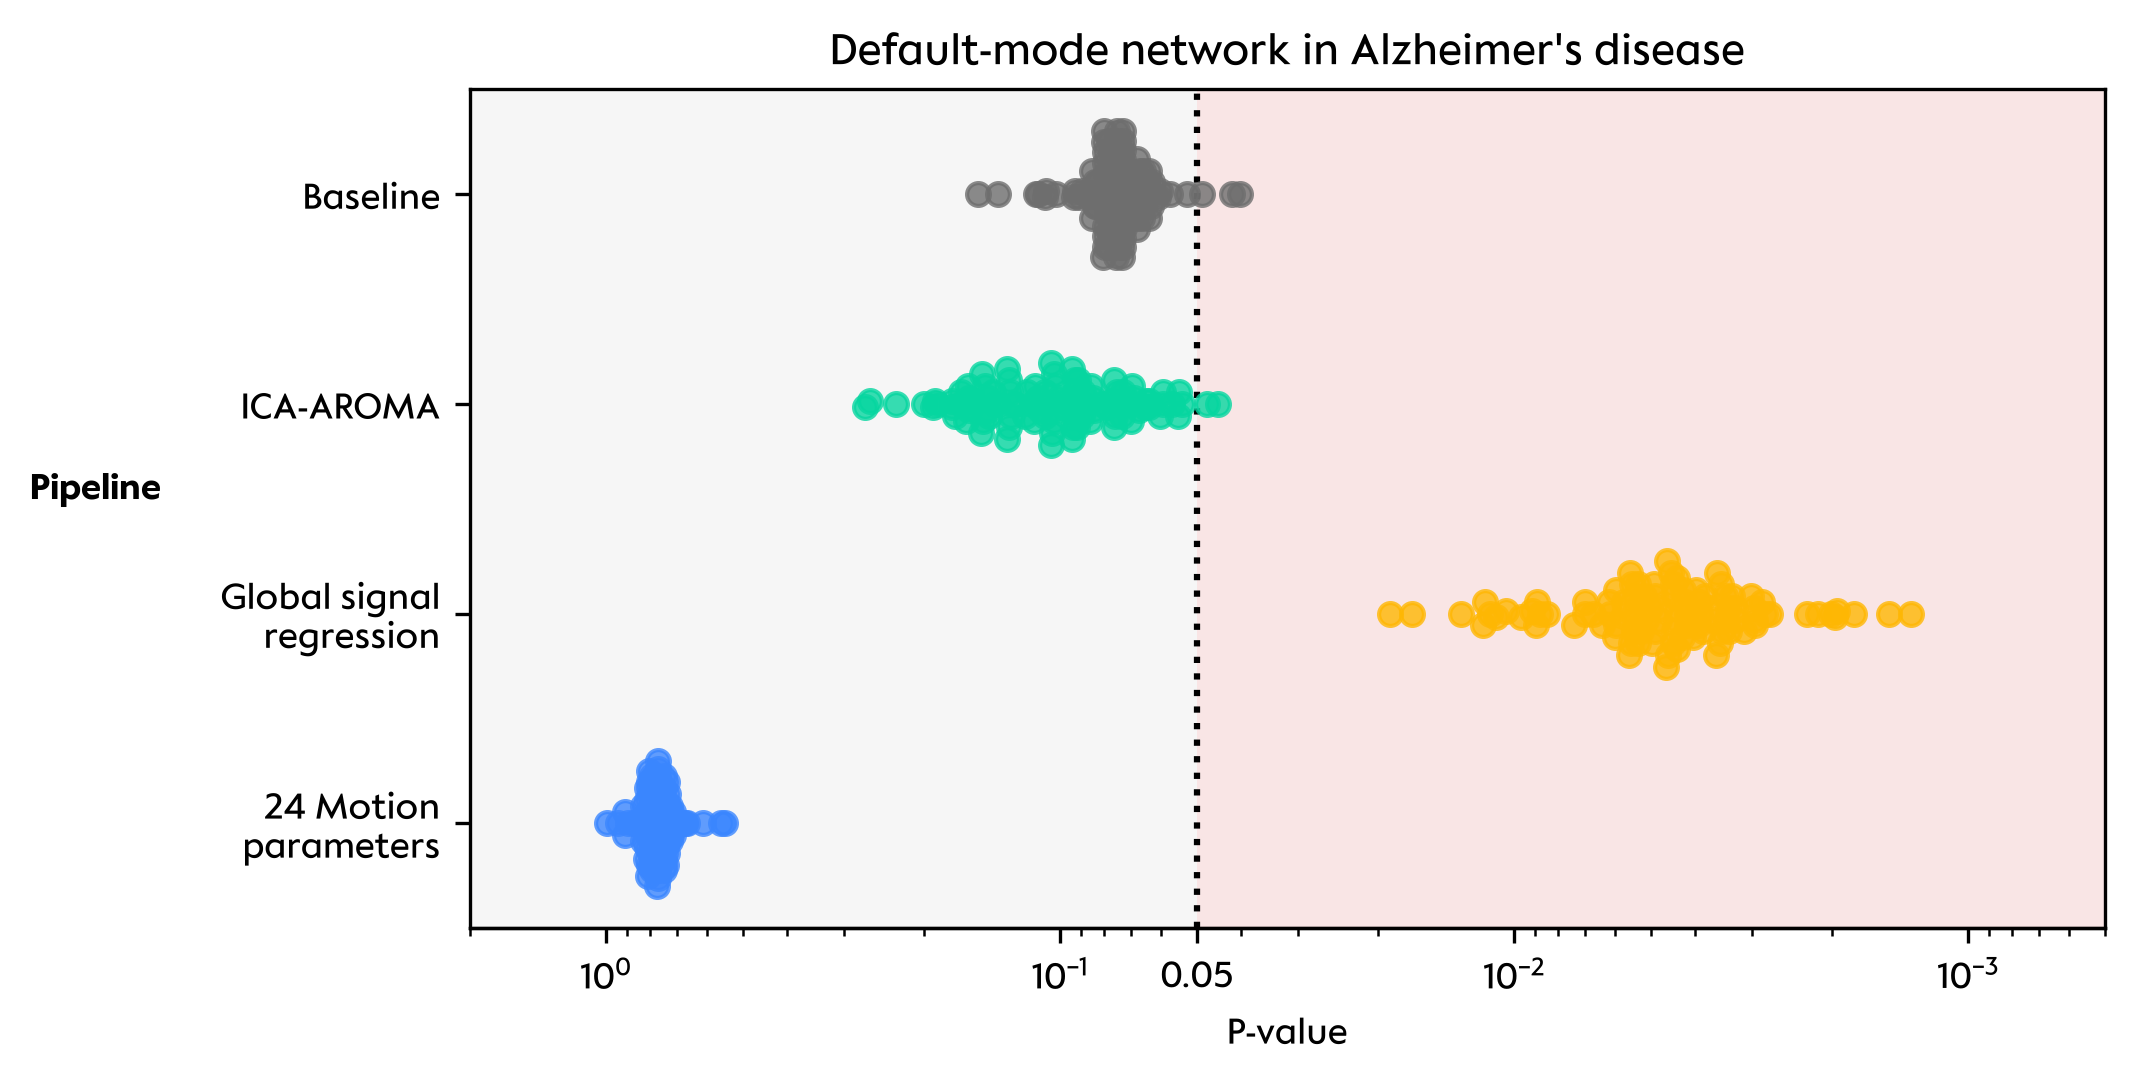

In [45]:
import pandas as pd

# Default mode network AD vs CN p-values across 100 repetitions per pipeline
pipelines = {
    "baseline": "Baseline",
    "icaAroma": "ICA-AROMA",
    "GSR": "Global signal\nregression",
    "motionParameters": "24 Motion\nparameters",
}
threshold = 0.05


COLORS = {
    "baseline": "#6E6E6E",
    "icaAroma": "#06D6A0",
    "GSR": "#FFB703",
    "motionParameters": "#3A86FF",
}


def swarm_offsets(values, bins=40, max_width=0.3):
    """Spread points that fall into the same value bin symmetrically around zero."""
    edges = np.linspace(values.min(), values.max(), bins + 1)
    bin_index = np.digitize(values, edges[1:-1])
    offsets = np.zeros(len(values))
    for b in np.unique(bin_index):
        index = np.flatnonzero(bin_index == b)
        index = index[np.argsort(values[index], kind="stable")]
        m = len(index)
        width = min(max_width, 0.028 * (m - 1))
        if m == 2:
            width /= 2
        steps = np.linspace(-width, width, m)
        offsets[index] = steps[np.argsort(np.abs(steps), kind="stable")]
    return offsets


figure, axes = plt.subplots(
    ncols=1, nrows=1, figsize=(7, 3.5), dpi=300, sharey=True, layout="constrained"
)

# for axes, path, title in zip(
#     axes_array,
#     [
#         "/work/charite/src/connectome-variability/gp_analysis/AD/output/pval/within_network_output_pval.csv",
#         # "/work/charite/src/connectome-variability/gp_analysis/SCZ/output/pval/within_network_output_pval.csv",
#     ],
#     [
#         "Default-mode network in Alzheimer's disease",
#         # "Sensorymotor in schizophrenia",
#     ],
# ):

title = "Default-mode network in Alzheimer's disease"
path = "/work/charite/src/connectome-variability/gp_analysis/AD/output/pval/within_network_output_pval.csv"

data = pd.read_csv(path)
data["pipeline"] = data.pipeline_iteration.str.extract(
    r"^pipeline-(.+)_repetition-\d+$", expand=False
).map(pipelines)
data = data[(data.network == "dmn") & data.pipeline.notna()]
for row, (key, pipeline) in enumerate(pipelines.items()):
    p = data.loc[data.pipeline == pipeline, "p_z"].to_numpy()
    axes.scatter(
        p,
        row + swarm_offsets(np.log10(p)),
        s=30,
        color=COLORS[key],
        alpha=0.8,
        # edgecolors="black",
        # linewidth=0.1,
        zorder=3,
    )

# Smaller p-values to the right
axes.set_xscale("log")
axes.set_xlim(2, 5e-4)
axes.set_ylim(len(pipelines) - 0.5, -0.5)

axes.axvspan(threshold, 5e-4, color="#f4cccc", alpha=0.5, linewidth=0, zorder=0)
axes.axvspan(2, threshold, color="#eeeeee", alpha=0.5, linewidth=0, zorder=0)
axes.axvline(threshold, color="black", linestyle=":", zorder=2)

# Label the threshold line with a tick on the top edge
top = axes.secondary_xaxis("bottom")
top.set_xticks([threshold], labels=[f"{threshold:g}"])
top.minorticks_off()

axes.set_ylabel("Pipeline", rotation=0, fontweight="bold", labelpad=30)
axes.set_yticks(range(len(pipelines)), pipelines.values())
axes.set_xlabel(r"$P$-value")

axes.set_title(title)


figure.savefig("swarm.svg", bbox_inches="tight", pad_inches=0, transparent=True)